In [1]:
from requirements import *

# Extended Data Figure 8

In [2]:
adata_cite = sc.read_h5ad(CITE)

## ED Figure 8a. CD4 and CD8 subset gene dotplots, Control vs MDS

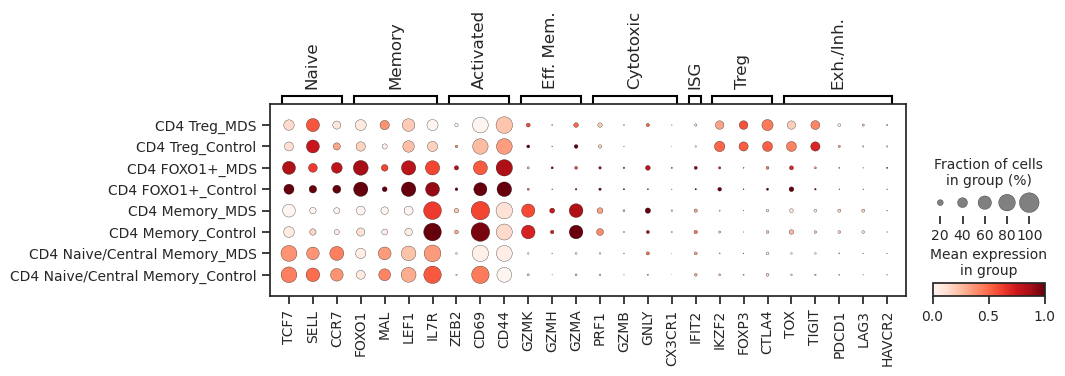

In [3]:
sns.set_style("ticks")
plt.rcParams['patch.edgecolor'] = 'black'

ct_dict = {
    'Naive': ['TCF7','SELL','CCR7',],
    'Memory': ['FOXO1','MAL','LEF1','IL7R'],
    'Activated': ['ZEB2','CD69','CD44'],
    'Eff. Mem.': ['GZMK','GZMH','GZMA'],
    'Cytotoxic': ['PRF1','GZMB','GNLY','CX3CR1'],
    'ISG': ['IFIT2'],
    'Treg': ['IKZF2','FOXP3','CTLA4'],
    'Exh./Inh.': ['TOX','TIGIT','PDCD1','LAG3','HAVCR2']
}
ctlst = ['CD4 Naive/Central Memory', 'CD4 Memory','CD4 FOXO1+','CD4 Treg']

ctlst.reverse()
tmp = adata_cite[adata_cite.obs['ct_refined'].isin(ctlst)]
tmp = tmp[tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'

order = list(zip([x + '_MDS' for x in ctlst], [x + '_Control' for x in ctlst]))
order = [[x,y] for x,y in order]
order = [item for sub in order for item in sub]

gene_list = list(itertools.chain.from_iterable(list(ct_dict.values())))
ct_pos = [[i for i,j in enumerate(gene_list) if j in val] for val in ct_dict.values()]
ct_pos = [(i[0],i[0]) if len(i)==1 else (i[0],i[-1]) for i in ct_pos]
ax = sc.pl.dotplot(tmp, gene_list, groupby=['ct_refined', 'type'], dendrogram=False, 
                   var_group_positions=ct_pos, mean_only_expressed = True, vmax = 1,
                   expression_cutoff = 0.3,standard_scale = 'var', categories_order = order,
                   use_raw = False, var_group_labels=list(ct_dict.keys()),
                   figsize=(10,2.5))


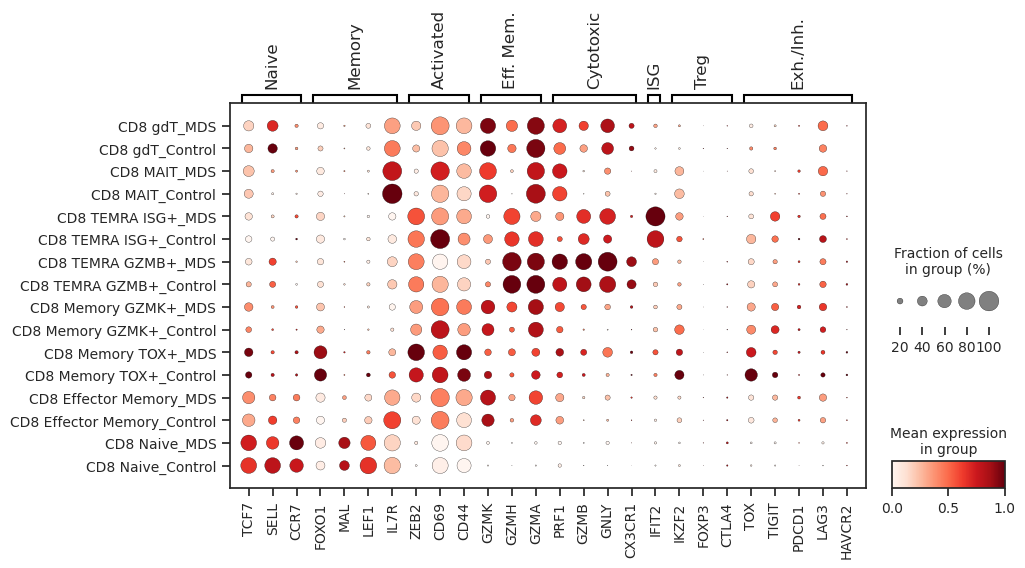

In [4]:
ct_dict = {
    'Naive': ['TCF7','SELL','CCR7',],
    'Memory': ['FOXO1','MAL','LEF1','IL7R'],
    'Activated': ['ZEB2','CD69','CD44'],
    'Eff. Mem.': ['GZMK','GZMH','GZMA'],
    'Cytotoxic': ['PRF1','GZMB','GNLY','CX3CR1'],
    'ISG': ['IFIT2'],
    'Treg': ['IKZF2','FOXP3','CTLA4'],
    'Exh./Inh.': ['TOX','TIGIT','PDCD1','LAG3','HAVCR2']
}
ctlst = ['CD8 Naive', 'CD8 Effector Memory', 'CD8 Memory TOX+', 'CD8 Memory GZMK+', 'CD8 TEMRA GZMB+', 'CD8 TEMRA ISG+', 'CD8 MAIT', 'CD8 gdT']
ctlst.reverse()
tmp = adata_cite[adata_cite.obs['ct_refined'].isin(ctlst)]
tmp = tmp[tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'

order = list(zip([x + '_MDS' for x in ctlst], [x + '_Control' for x in ctlst]))
order = [[x,y] for x,y in order]
order = [item for sub in order for item in sub]

gene_list = list(itertools.chain.from_iterable(list(ct_dict.values())))
ct_pos = [[i for i,j in enumerate(gene_list) if j in val] for val in ct_dict.values()]
ct_pos = [(i[0],i[0]) if len(i)==1 else (i[0],i[-1]) for i in ct_pos]
ax = sc.pl.dotplot(tmp, gene_list, groupby=['ct_refined', 'type'], dendrogram=False, 
                   var_group_positions=ct_pos, mean_only_expressed = True, vmax = 1,
                   expression_cutoff = 0.3,standard_scale = 'var', categories_order = order,
                   use_raw = False, var_group_labels=list(ct_dict.keys()),
                   figsize=(10,5)) 


## ED Figure 8b. CD4 and CD8 subset ADT (protein) dotplots, Control vs MDS


In [5]:
from scipy.sparse import hstack

adt_df = adata_cite.obs.loc[:, [x for x in adata_cite.obs.columns if x.startswith('ADT')]]
mat2 = adt_df.astype(pd.SparseDtype("float", 0)).sparse.to_coo()
adata_adt = AnnData(X=hstack([adata_cite.X, mat2]).tocsr())
adata_adt.obs = adata_cite.obs.loc[:, ['sample', 'ct_general', 'ct_refined', 'type']]
adata_adt.var_names = [x for x in adata_cite.var_names] + [x for x in adata_cite.obs.columns if x.startswith('ADT')]


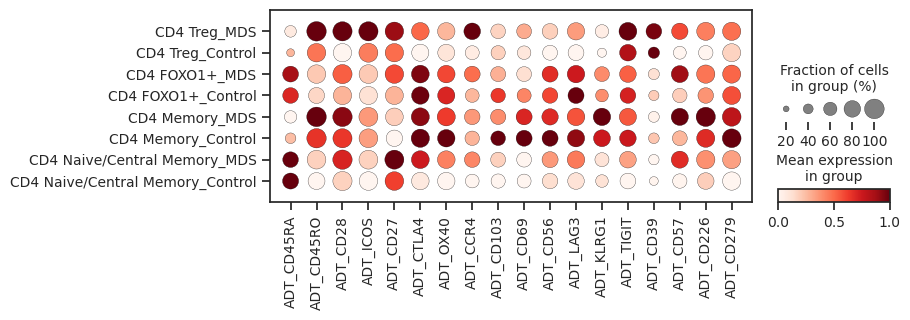

In [6]:
adt_markers = ['ADT_CD45RA', 'ADT_CD45RO','ADT_CD28', 'ADT_ICOS', 'ADT_CD27', 'ADT_CTLA4', 'ADT_OX40', 'ADT_CCR4', 'ADT_CD103', 'ADT_CD69', 'ADT_CD56', 'ADT_LAG3','ADT_KLRG1', 'ADT_TIGIT', 'ADT_CD39', 'ADT_CD57','ADT_CD226','ADT_CD279']
ctlst = ['CD4 Naive/Central Memory', 'CD4 Memory','CD4 FOXO1+','CD4 Treg']
ctlst.reverse()
tmp = adata_adt[adata_adt.obs['ct_refined'].isin(ctlst)]
tmp = tmp[tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'

order = list(zip([x + '_MDS' for x in ctlst], [x + '_Control' for x in ctlst]))
order = [[x,y] for x,y in order]
order = [item for sub in order for item in sub]

ax = sc.pl.dotplot(tmp, adt_markers, groupby=['ct_refined', 'type'], dendrogram=False, 
                   mean_only_expressed = True,
                   vmax = 1,
                   expression_cutoff = 0.3,
                   standard_scale = 'var',
                   use_raw = False, 
                   categories_order = order,
                   figsize=(8,2.5))

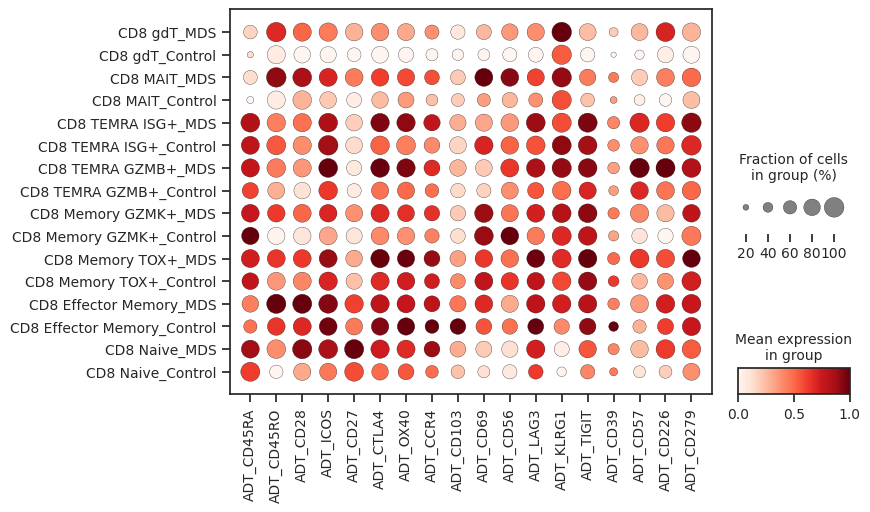

In [7]:
adt_markers = ['ADT_CD45RA', 'ADT_CD45RO','ADT_CD28', 'ADT_ICOS', 'ADT_CD27', 'ADT_CTLA4', 'ADT_OX40', 'ADT_CCR4', 'ADT_CD103', 'ADT_CD69', 'ADT_CD56', 'ADT_LAG3','ADT_KLRG1', 'ADT_TIGIT', 'ADT_CD39', 'ADT_CD57','ADT_CD226','ADT_CD279']
ctlst = ['CD8 Naive', 'CD8 Effector Memory', 'CD8 Memory TOX+', 'CD8 Memory GZMK+', 'CD8 TEMRA GZMB+', 'CD8 TEMRA ISG+', 'CD8 MAIT', 'CD8 gdT']
ctlst.reverse()
tmp = adata_adt[adata_adt.obs['ct_refined'].isin(ctlst)]
tmp = tmp[tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'

order = list(zip([x + '_MDS' for x in ctlst], [x + '_Control' for x in ctlst]))
order = [[x,y] for x,y in order]
order = [item for sub in order for item in sub]

ax = sc.pl.dotplot(tmp, adt_markers, groupby=['ct_refined', 'type'], dendrogram=False,  
                   mean_only_expressed = True,
                   vmax = 1,
                   expression_cutoff = 0.3,
                   standard_scale = 'var',
                   use_raw = False, 
                   categories_order = order,
                   figsize=(8,5))
